#  Swiggy Delivery Time Prediction — End-to-End Machine Learning System

---

##   Business Problem & Project Overview
Swiggy processes millions of food delivery orders across hundreds of cities every month. Accurate **Estimated Time of Arrival (ETA)** at order placement directly affects customer trust, conversion, cancellation rates, and rider efficiency.

###  Key Objectives:
1. **Predict Delivery Time (`time_taken` in minutes)** accurately at the moment of order placement.
2. **Prevent Data Leakage** by fitting all preprocessing transformations strictly on training data.
3. **Benchmark Dual Preprocessing Tracks**: Automated Scikit-Learn **Pipeline** vs. **Manual Step-by-Step**.
4. **Compare 6 Machine Learning Algorithms** (Linear Regression, Linear SVR, KNN, Decision Tree, Random Forest, XGBoost) and perform **Hyperparameter Tuning**.
5. **Serialize the Champion Model** (`Swiggy_delivery_time_required.pkl`) and deploy via **Streamlit**.

###   Importing Required Libraries
Load all core data manipulation (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), and machine learning (`scikit-learn`, `xgboost`, `joblib`) packages. Configures hardware acceleration for XGBoost.

In [1]:
# importing the required libraries
import importlib
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR, LinearSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
import pickle
import joblib

try:
    torch = importlib.import_module('torch')
    cuda_available = torch.cuda.is_available()
except ImportError:
    cuda_available = False

xgb_device = 'cuda' if cuda_available else 'cpu'
xgb_tree_method = 'hist'

print(f"Hardware Configured: XGBoost Device = '{xgb_device}', CPU Parallelism = n_jobs=-1")
print("All libraries imported successfully!")

Hardware Configured: XGBoost Device = 'cpu', CPU Parallelism = n_jobs=-1
All libraries imported successfully!


###   Loading the Swiggy Dataset
Load `swiggy_demographic.csv` into a pandas DataFrame.

In [2]:

df = pd.read_csv('swiggy_demographic.csv')


###   Inspecting Initial Data Records
Display the first and last rows to understand feature columns and sample values.

In [3]:
df


,rider_id,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,weather,traffic,...,time_taken,city_name,order_day,order_month,order_day_of_week,is_weekend,pickup_time_minutes,order_time_hour,order_time_of_day,distance
0,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,sunny,high,...,24,INDO,19,3,saturday,1,15.0,11.0,morning,3.025149
1,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,stormy,jam,...,33,BANG,25,3,friday,0,5.0,19.0,evening,20.183530
2,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,sandstorms,low,...,26,BANG,19,3,saturday,1,15.0,8.0,morning,1.552758
3,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,sunny,medium,...,21,COIMB,5,4,tuesday,0,10.0,18.0,evening,7.790401
4,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,cloudy,high,...,30,CHEN,26,3,saturday,1,15.0,13.0,afternoon,6.210138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45497,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,2022-03-24,windy,high,...,32,JAP,24,3,thursday,0,10.0,11.0,morning,1.489846
45498,AGRRES16DEL01,21.0,4.6,NaN,NaN,NaN,NaN,2022-02-16,windy,jam,...,36,AGR,16,2,wednesday,0,15.0,19.0,evening,NaN
45499,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,2022-03-11,cloudy,low,...,16,CHEN,11,3,friday,0,15.0,23.0,night,4.657195
45500,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,2022-03-07,cloudy,high,...,26,COIMB,7,3,monday,0,5.0,13.0,afternoon,6.232393


###   Checking Data Types & Non-Null Counts
Verify data types (`float64`, `int64`, `object`) and identify initial missing values across all 26 columns.

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45502 entries, 0 to 45501
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rider_id              45502 non-null  object 
 1   age                   43648 non-null  float64
 2   ratings               43594 non-null  float64
 3   restaurant_latitude   41872 non-null  float64
 4   restaurant_longitude  41872 non-null  float64
 5   delivery_latitude     41872 non-null  float64
 6   delivery_longitude    41872 non-null  float64
 7   order_date            45502 non-null  object 
 8   weather               44977 non-null  object 
 9   traffic               44992 non-null  object 
 10  vehicle_condition     45502 non-null  int64  
 11  type_of_order         45502 non-null  object 
 12  type_of_vehicle       45502 non-null  object 
 13  multiple_deliveries   44509 non-null  float64
 14  festival              45274 non-null  object 
 15  city_type          

###  Checking Dataset Dimensions
Check total rows and columns in the dataset.

In [5]:

df.shape


(45502, 26)

###  Summary Statistics for Numerical Features
Review central tendency (mean, median), dispersion (std, min, max), and quartiles.

In [6]:

df.describe()


,age,ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,vehicle_condition,multiple_deliveries,time_taken,order_day,order_month,is_weekend,pickup_time_minutes,order_time_hour,distance
count,43648.000000,43594.000000,41872.000000,41872.000000,41872.000000,41872.000000,45502.000000,44509.000000,45502.000000,45502.000000,45502.000000,45502.000000,43862.000000,43862.000000,41872.000000
mean,29.555008,4.635287,18.913696,76.921664,18.977356,76.985325,1.019406,0.744928,26.297591,13.811657,2.980726,0.274867,9.989399,17.423966,9.719296
std,5.761482,0.313827,5.467265,3.503107,5.469056,3.503260,0.835229,0.572488,9.386419,8.709540,0.546031,0.446452,4.087516,4.817856,5.602890
min,20.000000,2.500000,9.957144,72.768726,9.967144,72.778726,0.000000,0.000000,10.000000,1.000000,2.000000,0.000000,5.000000,0.000000,1.465067
25%,25.000000,4.500000,12.986047,73.897902,13.065996,73.940327,0.000000,0.000000,19.000000,6.000000,3.000000,0.000000,5.000000,15.000000,4.657655
50%,30.000000,4.700000,19.065838,76.618203,19.124049,76.662620,1.000000,1.000000,26.000000,13.000000,3.000000,0.000000,10.000000,19.000000,9.193014
75%,35.000000,4.900000,22.751234,78.368855,22.820040,78.405467,2.000000,1.000000,32.000000,20.000000,3.000000,1.000000,15.000000,21.000000,13.680920
max,39.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000,31.000000,4.000000,1.000000,15.000000,23.000000,20.969489


###   Duplicate Column / Row Verification
Check for duplicated columns or rows to ensure data uniqueness.

In [7]:
# checking the duplicate values
df.T.duplicated().sum()


np.int64(0)

###  Missing Value (NaN) Assessment
Count missing values per column to plan appropriate imputation strategies.

In [8]:

df.isna().sum()


rider_id                   0
age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
order_date                 0
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

---
##   Exploratory Data Analysis (EDA)
In this section, we analyze distributions, trends, and relationships across numerical, categorical, and target features.

###   Separating Numerical & Categorical Features
Partition feature names into `num_cols` and `cat_cols` for structured visual exploration.

In [9]:

num_cols = ['vehicle_condition', 'multiple_deliveries', 'is_weekend', 'pickup_time_minutes', 'distance', 'age', 'ratings', 'order_day', 'order_month', 'order_time_hour']
cat_cols = ['weather', 'traffic', 'type_of_order', 'type_of_vehicle', 'festival', 'city_name', 'city_type', 'order_time_of_day', 'order_day_of_week']
print("Numerical columns count:", len(num_cols))
print("Categorical columns count:", len(cat_cols))


Numerical columns count: 10
Categorical columns count: 9


###   Univariate Analysis — Numerical Distributions
Plot histograms and KDE curves for numerical features (`age`, `ratings`, `distance`, `pickup_time_minutes`, `time_taken`, etc.).

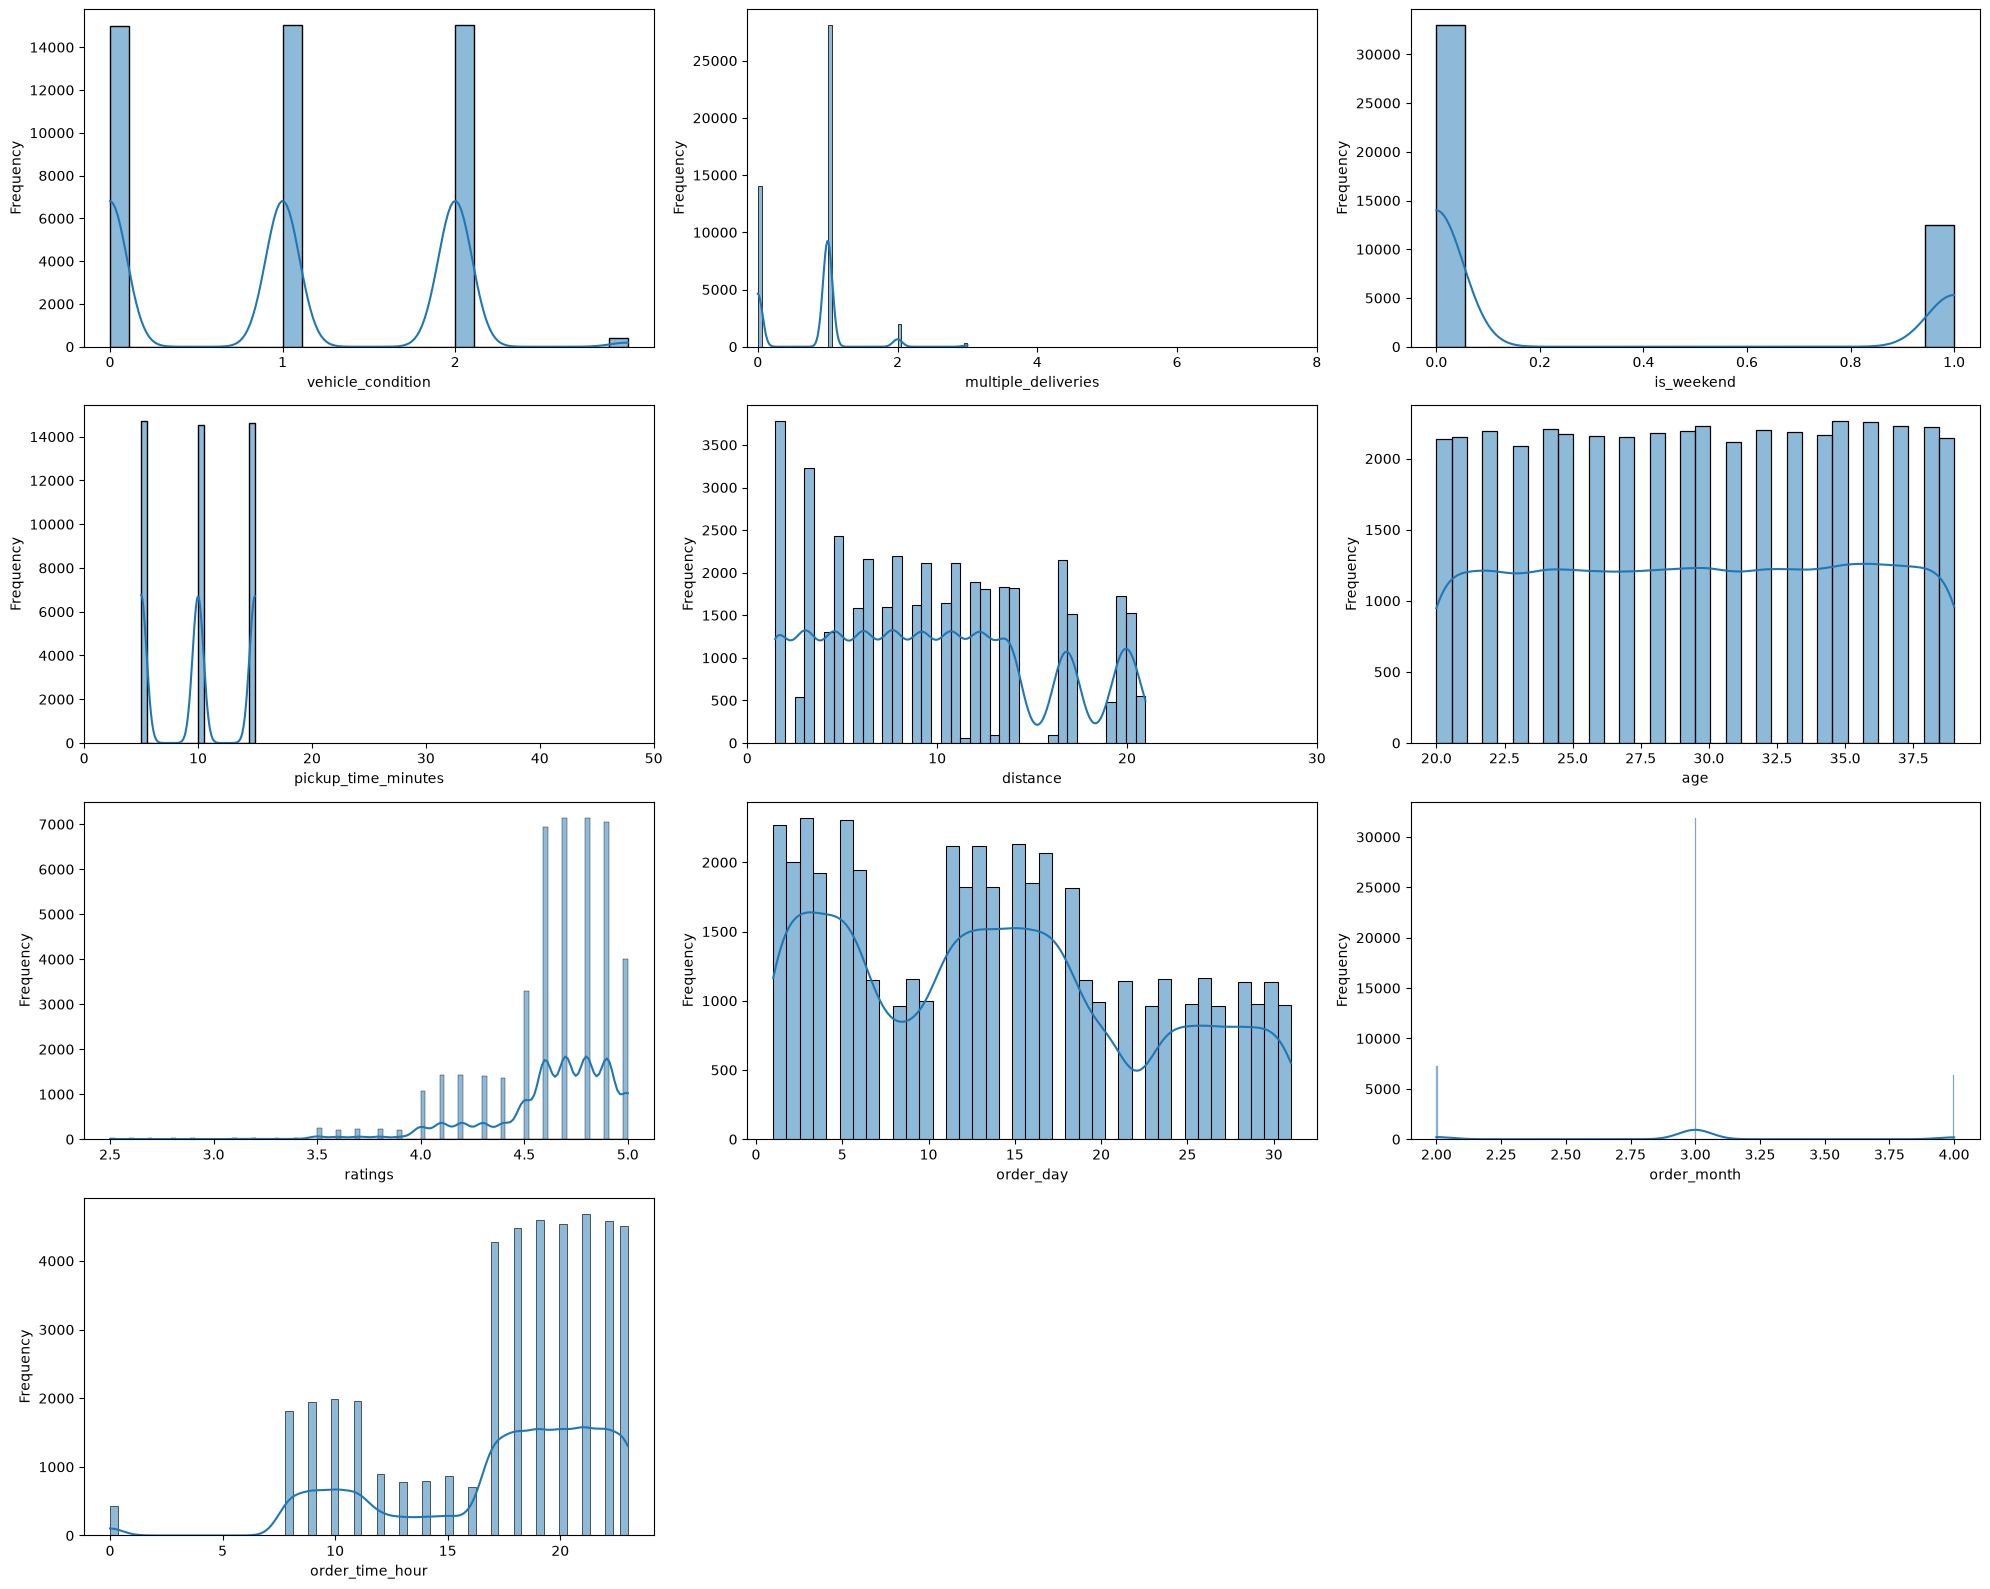

In [10]:

plt.figure(figsize=(20, 16))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.histplot(df[col], kde=True)
    if col == 'vehicle_condition':
        plt.xticks([0, 1, 2])
    elif col == 'multiple_deliveries':
        plt.xticks(range(0, 10, 2))
    elif col == 'pickup_time_minutes':
        plt.xticks(range(0, 60, 10))
    elif col == 'distance':
        plt.xticks(range(0, 40, 10))
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


###  Univariate Analysis — Categorical Frequency
Plot count distributions for weather conditions, traffic levels, order types, vehicle types, and festival indicators.

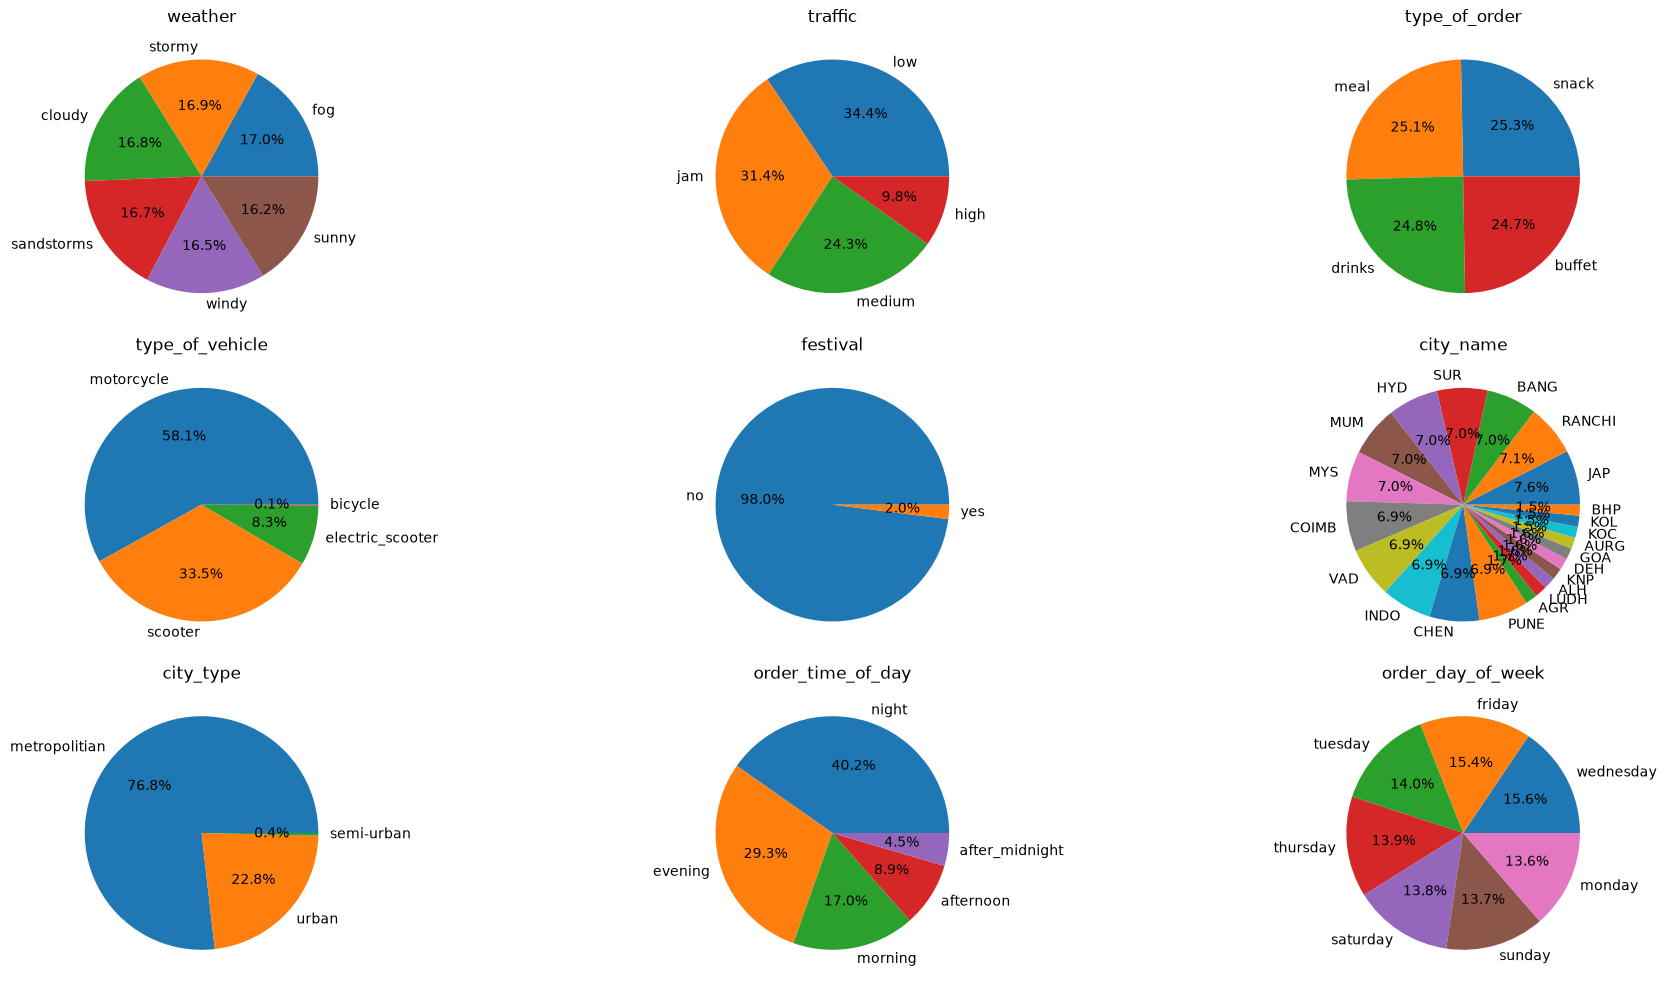

In [11]:

plt.figure(figsize=(20, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    count = df[col].value_counts()
    plt.pie(count, labels=count.index, autopct='%1.1f%%')
    plt.title(col)
plt.tight_layout()
plt.show()


###  City-Wise Order Volume Distribution
Visualize order frequencies across major cities (`BANG`, `HYD`, `CHEN`, `MUM`, `DEL`, etc.).

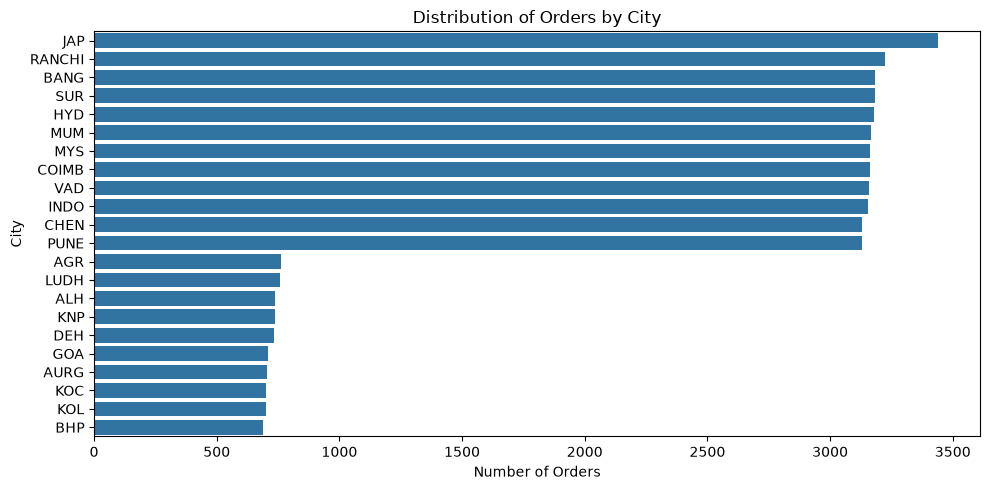

In [12]:
plt.figure(figsize=(10, 5))
city_count = df['city_name'].value_counts()
sns.barplot(x=city_count.values, y=city_count.index)
plt.title('Distribution of Orders by City')
plt.xlabel('Number of Orders')
plt.ylabel('City')
plt.tight_layout()
plt.show()


###   Bivariate Analysis — Numerical Features vs. Delivery Time (`time_taken`)
Scatter / regression plots showing how delivery distance, pickup prep time, and rider age impact delivery time.

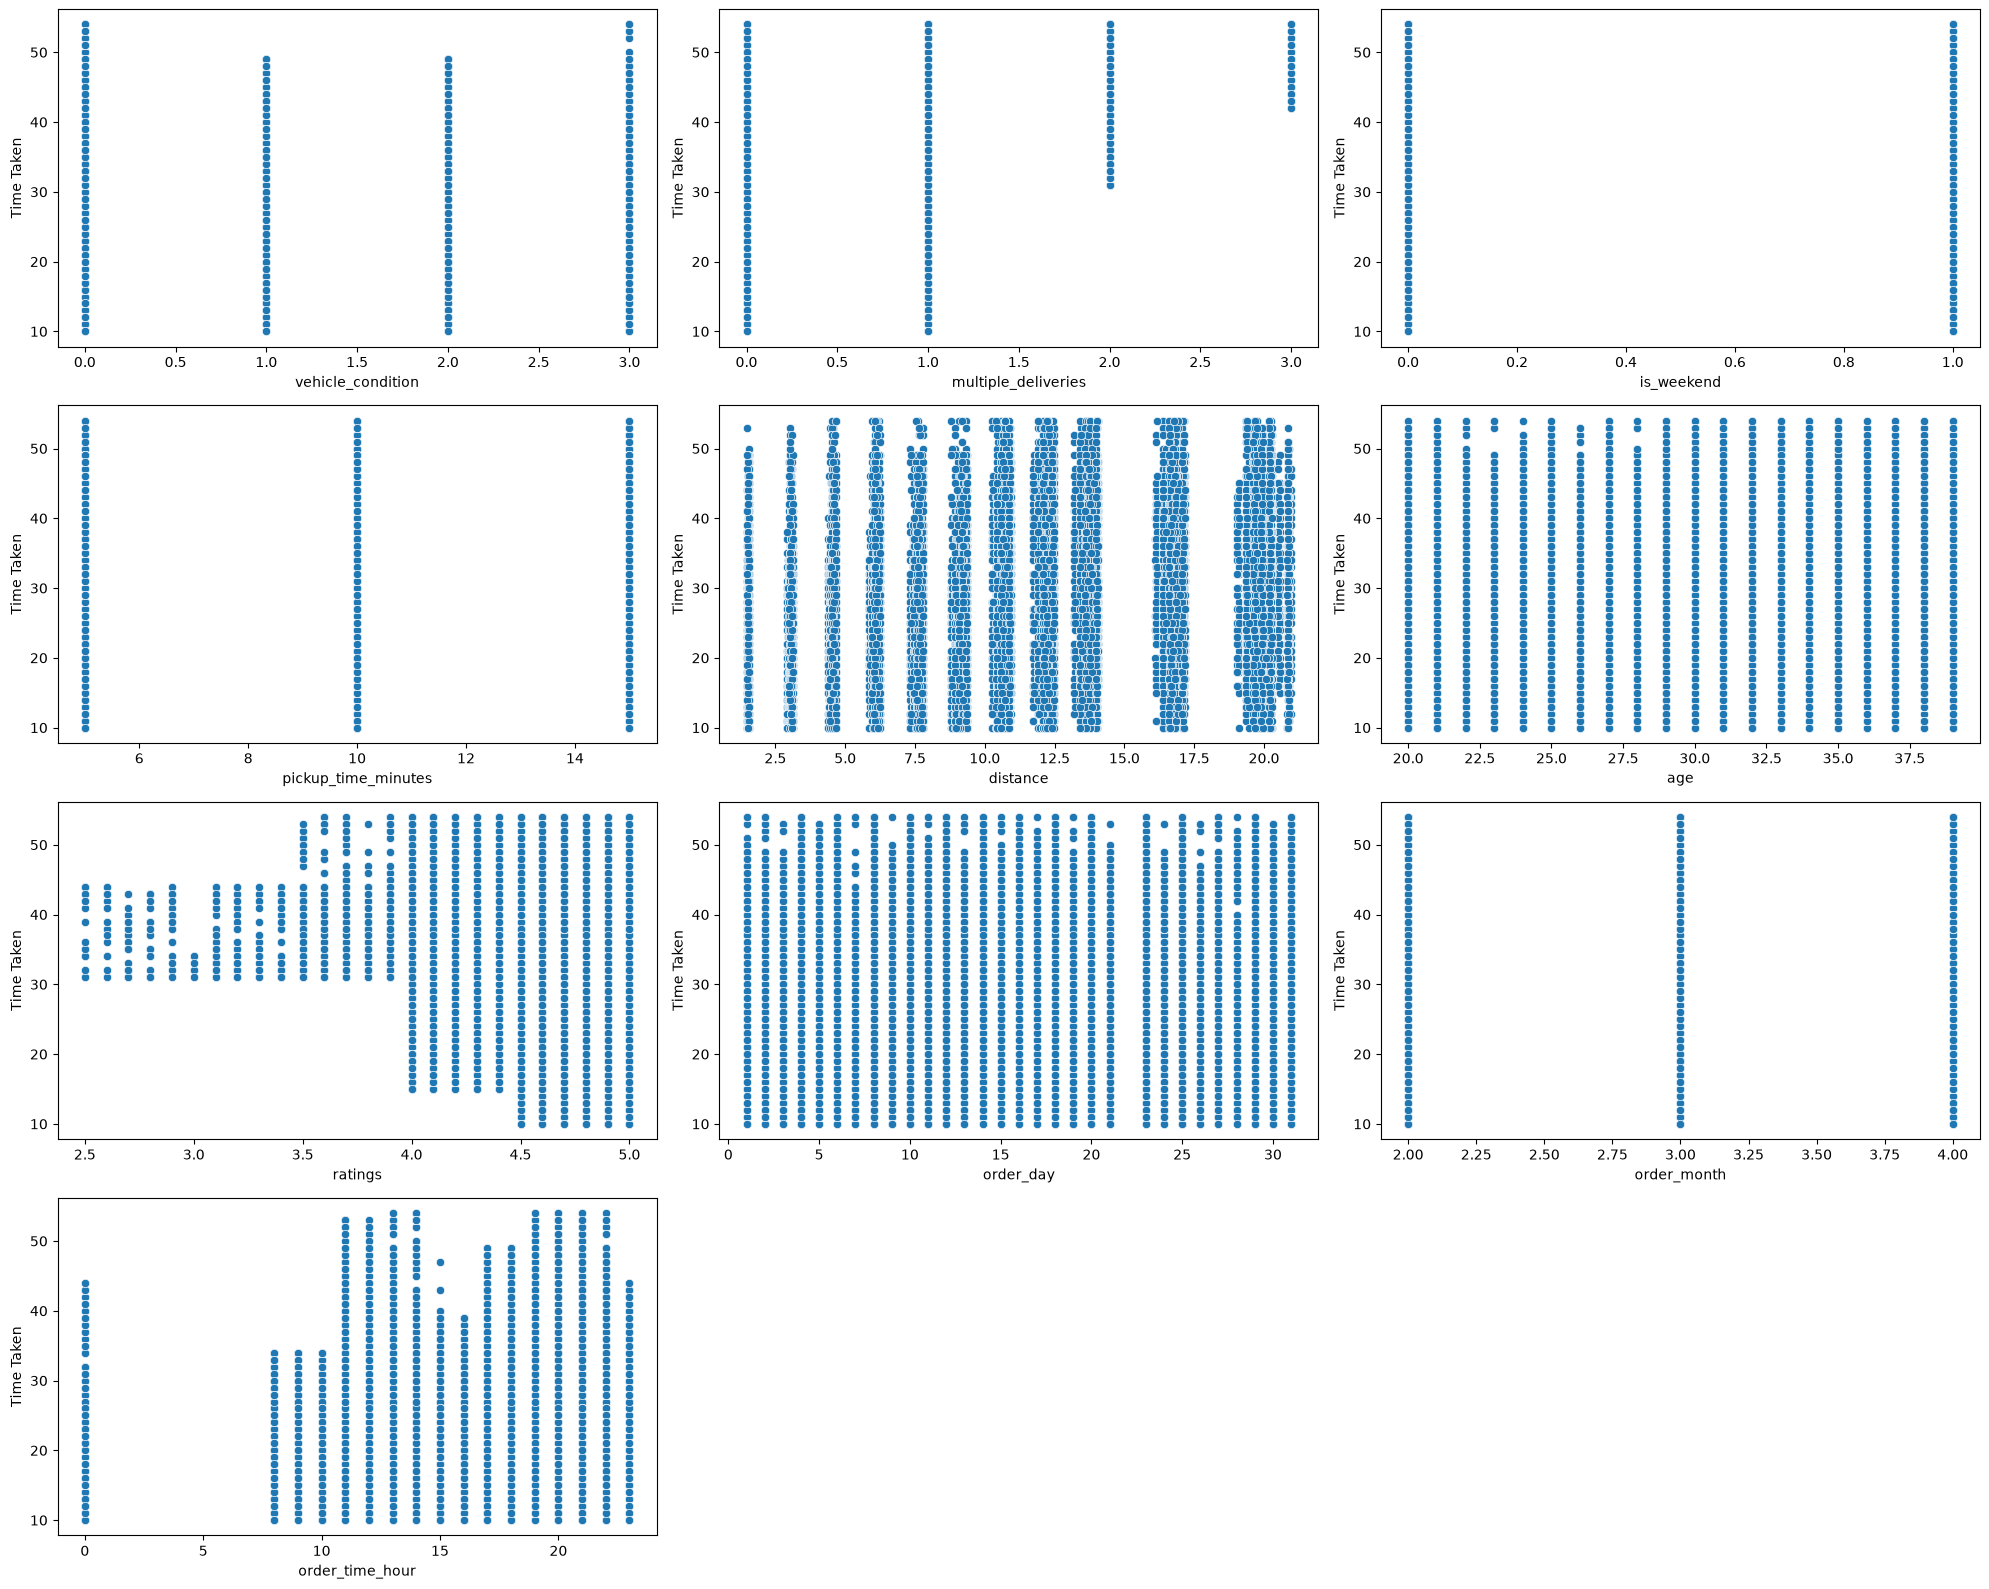

In [13]:

plt.figure(figsize=(20, 16))
for i, col in enumerate(num_cols, 1):
    plt.subplot(4, 3, i)
    sns.scatterplot(data=df, x=col, y='time_taken')
    plt.xlabel(col)
    plt.ylabel('Time Taken')
plt.tight_layout()
plt.show()


###  Bivariate Analysis — Categorical Features vs. Delivery Time
Boxplots examining the effect of traffic jams, stormy weather, festival days, and city types on delivery duration.

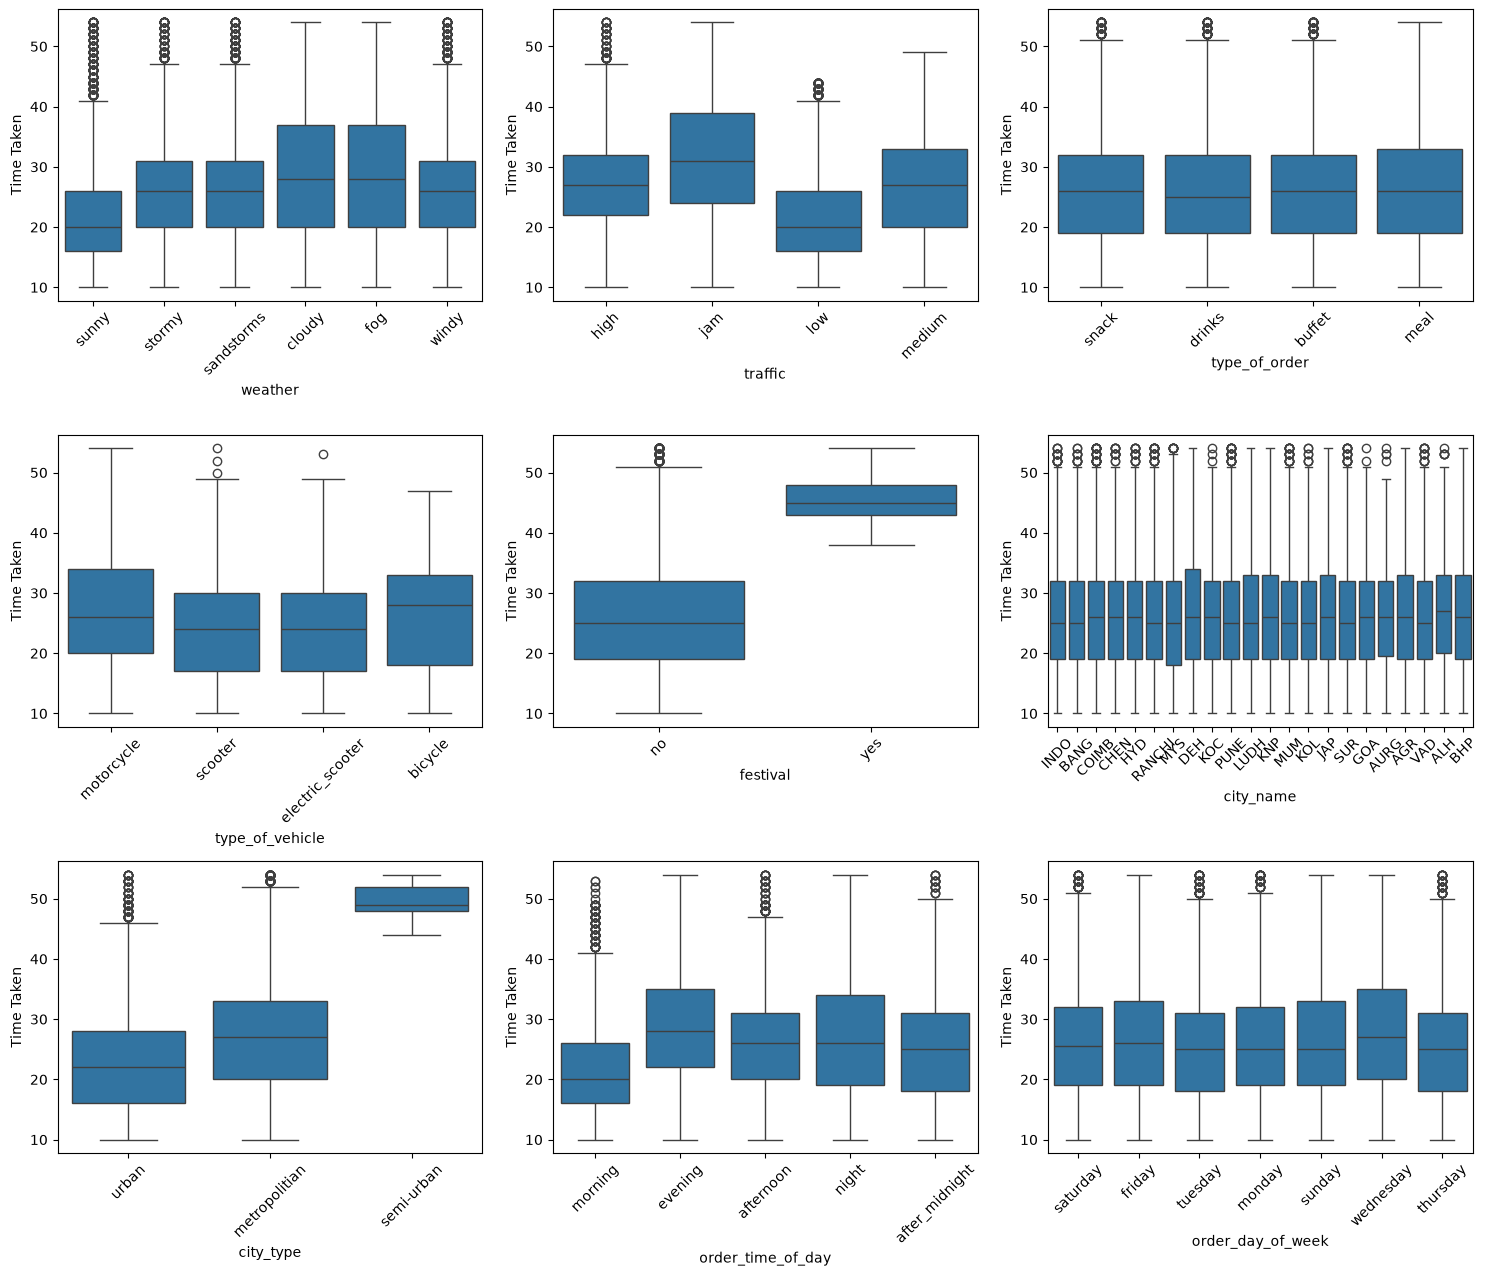

In [14]:

plt.figure(figsize=(15, 16))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(data=df, x=col, y='time_taken')
    plt.xlabel(col)
    plt.ylabel('Time Taken')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


###   Multivariate Correlation Heatmap
Compute Pearson correlation matrix across numerical variables to identify strong linear associations and collinearity.

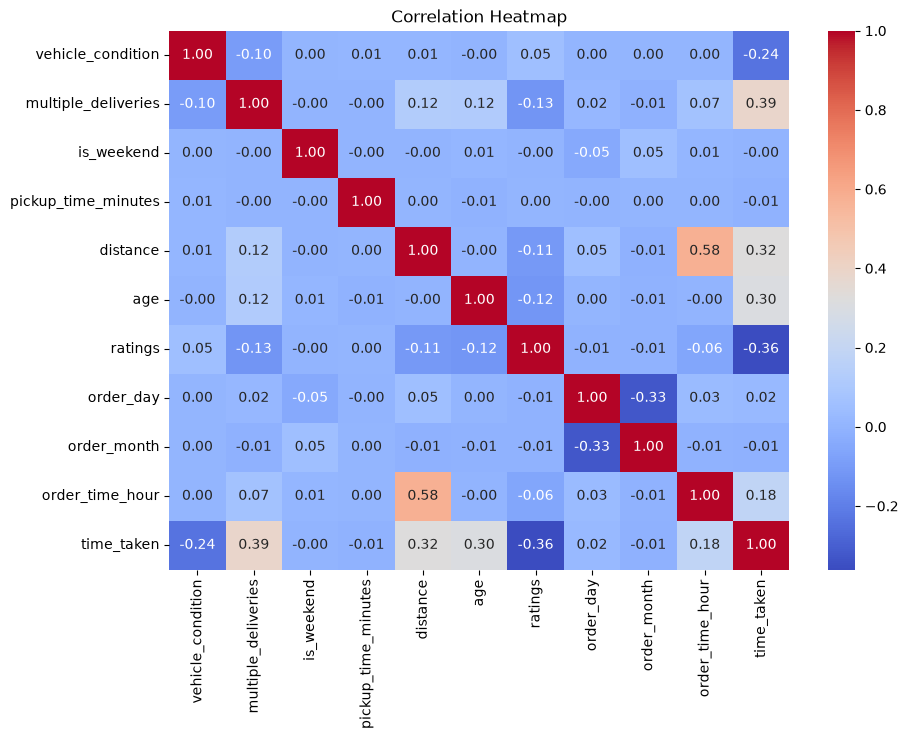

In [15]:

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols + ['time_taken']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


###  Target Variable (`time_taken`) Distribution & Spread
Detailed inspection of delivery time target distribution, mean, median, and spread.

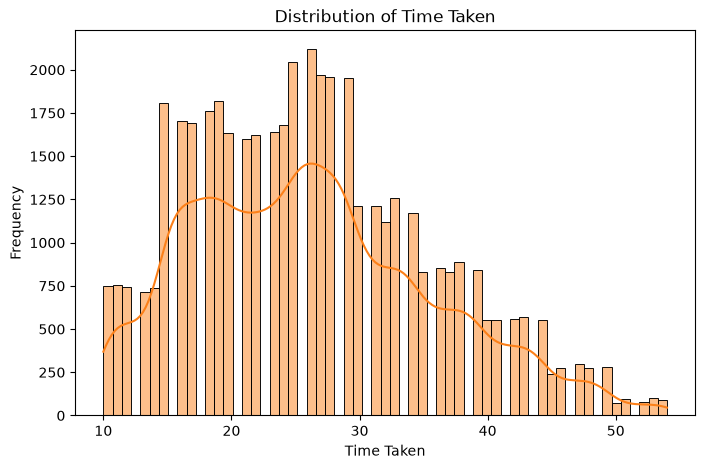

In [16]:

plt.figure(figsize=(8, 5))
sns.histplot(df['time_taken'], kde=True, color='#FC8019')
plt.xlabel('Time Taken')
plt.ylabel('Frequency')
plt.title('Distribution of Time Taken')
plt.show()


###  Skewness Analysis of Numerical Features
Calculate skewness values to determine which features require Power Transformation (Yeo-Johnson).

In [17]:

df[num_cols + ['time_taken']].skew()


vehicle_condition      0.060683
multiple_deliveries    0.325004
is_weekend             1.008587
pickup_time_minutes    0.003900
distance               0.325018
age                   -0.014542
ratings               -1.793118
order_day              0.299094
order_month           -0.012456
order_time_hour       -1.023568
time_taken             0.485582
dtype: float64

---
##   Data Preprocessing & Modeling (Track 1: With Pipeline)
Here we construct an automated, end-to-end Scikit-Learn `ColumnTransformer` preprocessing pipeline that seamlessly handles missing value imputation, power transformation, scaling, one-hot encoding, and ordinal encoding.

###   Grouping Nominal and Ordinal Columns
- **Nominal Features** (unordered): `weather`, `type_of_order`, `type_of_vehicle`, `festival`, `city_name`
- **Ordinal Features** (ordered hierarchy): `traffic`, `city_type`, `order_time_of_day`, `order_day_of_week`

In [18]:

nominal_cols = ['weather', 'type_of_order', 'type_of_vehicle', 'festival', 'city_name']
ordinal_cols = ['traffic', 'city_type', 'order_time_of_day', 'order_day_of_week']

print("Nominal cols:", nominal_cols)
print("Ordinal cols:", ordinal_cols)


Nominal cols: ['weather', 'type_of_order', 'type_of_vehicle', 'festival', 'city_name']
Ordinal cols: ['traffic', 'city_type', 'order_time_of_day', 'order_day_of_week']


###   Defining Feature Matrix ($X$) and Target Vector ($y$)
Select the 19 relevant features for prediction and isolate `time_taken` as the regression target.

In [19]:

X = df[['vehicle_condition', 'multiple_deliveries', 'is_weekend', 'pickup_time_minutes', 'distance', 'age', 'ratings', 'order_day', 'order_month', 'order_time_hour', 'weather', 'traffic', 'type_of_order', 'type_of_vehicle', 'festival', 'city_name', 'city_type', 'order_time_of_day', 'order_day_of_week']]
y = df['time_taken']

for i in X.columns:
    print(f"{i}: {X[i].nunique()} unique values")


vehicle_condition: 4 unique values
multiple_deliveries: 4 unique values
is_weekend: 2 unique values
pickup_time_minutes: 3 unique values
distance: 4362 unique values
age: 20 unique values
ratings: 26 unique values
order_day: 30 unique values
order_month: 3 unique values
order_time_hour: 17 unique values
weather: 6 unique values
traffic: 4 unique values
type_of_order: 4 unique values
type_of_vehicle: 4 unique values
festival: 2 unique values
city_name: 22 unique values
city_type: 3 unique values
order_time_of_day: 5 unique values
order_day_of_week: 7 unique values


###  Train-Test Split (80% Train, 20% Test)
Split the dataset into training (36,401 samples) and test (9,101 samples) sets with `random_state=23` to ensure reproducible benchmarking.

In [20]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)
print(f"X_train Shape: {X_train.shape}, X_test Shape: {X_test.shape}")


X_train Shape: (36401, 19), X_test Shape: (9101, 19)


###   Building the Numerical Transformer Pipeline
Pipeline stages:
1. `SimpleImputer(strategy='mean')` — handles any missing numeric values.
2. `PowerTransformer()` — applies Yeo-Johnson transformation to normalize skewed features.
3. `StandardScaler()` — scales numerical features to zero mean and unit variance.

In [21]:

numeric_transformer = Pipeline([
    ('Mean Imputation', SimpleImputer(strategy='mean')),
    ('Transformation', PowerTransformer()),
    ('Scaling', StandardScaler())
])


Inspect the numerical transformer architecture:

In [22]:
numeric_transformer


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Mean Imputation', ...), ('Transformation', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive est

###   Building the Nominal Transformer Pipeline
Pipeline stages:
1. `SimpleImputer(strategy='most_frequent')` — imputes missing categories with mode.
2. `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` — creates dummy columns.

In [23]:

nominal_transformer = Pipeline([
    ('Mode Imputation', SimpleImputer(strategy='most_frequent')),
    ('One Hot encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


Inspect the nominal transformer architecture:

In [24]:
nominal_transformer


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Mode Imputation', ...), ('One Hot encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predicti

###   Inspecting Ordinal Category Levels
Check unique category values for `traffic` to define the ordinal hierarchy.

In [25]:

df['traffic'].unique()


array(['high', 'jam', 'low', 'medium', nan], dtype=object)

Check unique category values for `city_type`:

In [26]:

df['city_type'].unique()


array(['urban', 'metropolitian', 'semi-urban', nan], dtype=object)

Check unique category values for `order_time_of_day`:

In [27]:

df['order_time_of_day'].unique()


array(['morning', 'evening', 'afternoon', 'night', 'after_midnight'],
      dtype=object)

Check unique category values for `order_day_of_week`:

In [28]:
df['order_day_of_week'].unique()


array(['saturday', 'friday', 'tuesday', 'monday', 'sunday', 'wednesday',
       'thursday'], dtype=object)

###  Defining Explicit Ordinal Category Hierarchy (`cat_order`)
Define the ranked lists from low to high:
- Traffic: `low` < `medium` < `high` < `jam`
- City Type: `semi-urban` < `urban` < `metropolitian`
- Time of Day: `morning` < `afternoon` < `evening` < `night` < `after_midnight`
- Day of Week: `sunday` through `saturday`

In [29]:
cat_order = [
    ['low', 'medium', 'high', 'jam'],
    ['semi-urban', 'urban', 'metropolitian'],
    ['morning', 'afternoon', 'evening', 'night', 'after_midnight'],
    ['sunday', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday']
]


###   Building the Ordinal Transformer Pipeline
Imputes missing values with mode, then maps categorical strings to ordinal integers based on `cat_order`.

In [30]:
ordinal_transformer = Pipeline([
    ('Mode Imputation', SimpleImputer(strategy='most_frequent')),
    ('Ordinal Encoding', OrdinalEncoder(categories=cat_order, handle_unknown='use_encoded_value', unknown_value=-1))
])


Inspect the ordinal transformer architecture:

In [31]:
ordinal_transformer


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Mode Imputation', ...), ('Ordinal Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predicti

###   Assembling the Master `ColumnTransformer` (`preprocessing`)
Combines Numerical, Nominal, and Ordinal transformers into a single unified preprocessing object.

In [32]:

preprocessing = ColumnTransformer([
    ('Numerical Transformer', numeric_transformer, num_cols),
    ('Nominal Transformer', nominal_transformer, nominal_cols),
    ('Ordinal Transformer', ordinal_transformer, ordinal_cols)
])


Inspect the assembled `ColumnTransformer` layout:

In [33]:
preprocessing


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``

---
##   Model Building & Evaluation (Track 1: Pipeline)
We evaluate 6 regression algorithms wrapped inside end-to-end Scikit-Learn pipelines. Each model is trained on `X_train` and evaluated on `X_test` using MAE, MSE, RMSE, and $R^2$ score.

###  Model 1: Linear Regression (Pipeline Baseline)
Fit ordinary least squares linear regression using parallel processing (`n_jobs=-1`).

In [34]:

lr = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', LinearRegression(n_jobs=-1))
])
lr.fit(X_train, y_train)
y_test_pred = lr.predict(X_test)
y_train_pred = lr.predict(X_train)
print('training MAE:', mean_absolute_error(y_train, y_train_pred))
print('testing MAE:', mean_absolute_error(y_test, y_test_pred))
print('training MSE:', mean_squared_error(y_train, y_train_pred))
print('testing MSE:', mean_squared_error(y_test, y_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE:', r2_score(y_train, y_train_pred))
print('testing R2 SCORE:', r2_score(y_test, y_test_pred))


training MAE: 5.004684461593265
testing MAE: 4.970624067621569
training MSE: 39.55753058676551
testing MSE: 38.728674178881064
training RMSE: 6.289477767411656
testing RMSE: 6.223236632081498
training R2 SCORE: 0.5499424780999645
testing R2 SCORE: 0.5644072646154411


Inspect Linear Regression pipeline:

In [35]:
lr


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###  Model 2: Support Vector Regressor (LinearSVR)
Support Vector Regression with linear loss function for fast convergence on large tabular datasets.

In [36]:

svr = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', LinearSVR(random_state=23, max_iter=2000))
])
svr.fit(X_train, y_train)
y_test_pred = svr.predict(X_test)
y_train_pred = svr.predict(X_train)
print('training MAE:', mean_absolute_error(y_train, y_train_pred))
print('testing MAE:', mean_absolute_error(y_test, y_test_pred))
print('training MSE:', mean_squared_error(y_train, y_train_pred))
print('testing MSE:', mean_squared_error(y_test, y_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE:', r2_score(y_train, y_train_pred))
print('testing R2 SCORE:', r2_score(y_test, y_test_pred))


training MAE: 4.986841503631114
testing MAE: 4.956705195619962
training MSE: 39.847857139060714
testing MSE: 39.03665518949765
training RMSE: 6.312515911984755
testing RMSE: 6.247932073054064
training R2 SCORE: 0.5466393485382959
testing R2 SCORE: 0.5609433120349488


Inspect SVR pipeline:

In [37]:
svr


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###  Model 3: K-Nearest Neighbors Regressor (KNN)
Non-parametric instance-based regression using $K=7$ nearest neighbors (`n_jobs=-1`).

In [38]:

knn = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', KNeighborsRegressor(n_neighbors=7, n_jobs=-1))
])
knn.fit(X_train, y_train)
y_test_pred = knn.predict(X_test)
y_train_pred = knn.predict(X_train)
print('training MAE:', mean_absolute_error(y_train, y_train_pred))
print('testing MAE:', mean_absolute_error(y_test, y_test_pred))
print('training MSE:', mean_squared_error(y_train, y_train_pred))
print('testing MSE:', mean_squared_error(y_test, y_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE:', r2_score(y_train, y_train_pred))
print('testing R2 SCORE:', r2_score(y_test, y_test_pred))


training MAE: 3.9806559474425747
testing MAE: 4.609477765394698
training MSE: 25.883666012763722
testing MSE: 34.34222747444215
training RMSE: 5.087599238615766
testing RMSE: 5.860224182950867
training R2 SCORE: 0.7055140093277212
testing R2 SCORE: 0.613742914727808


Inspect KNN pipeline:

In [39]:
knn


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###  Model 4: Decision Tree Regressor
Non-linear tree-based regression model capturing feature splits and interactions.

In [40]:

dt = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', DecisionTreeRegressor(random_state=23))
])
dt.fit(X_train, y_train)
y_test_pred = dt.predict(X_test)
y_train_pred = dt.predict(X_train)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  0.0
testing MAE:  4.179101197670586
training MSE:  0.0
testing MSE:  30.681903087572795
training RMSE:  0.0
testing RMSE:  5.5391247582603516
training R2 SCORE:  1.0
testing R2 SCORE:  0.6549116545794982


Inspect Decision Tree pipeline:

In [41]:
dt


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###  Model 5: Random Forest Regressor
Bagging ensemble combining 100+ decision trees with parallel processing (`n_jobs=-1`).

In [42]:

rf = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', RandomForestRegressor(random_state=23, n_jobs=-1))
])
rf.fit(X_train, y_train)
y_test_pred = rf.predict(X_test)
y_train_pred = rf.predict(X_train)
print('training MAE:', mean_absolute_error(y_train, y_train_pred))
print('testing MAE:', mean_absolute_error(y_test, y_test_pred))
print('training MSE:', mean_squared_error(y_train, y_train_pred))
print('testing MSE:', mean_squared_error(y_test, y_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE:', r2_score(y_train, y_train_pred))
print('testing R2 SCORE:', r2_score(y_test, y_test_pred))


training MAE: 1.1956009450289826
testing MAE: 3.211525107131084
training MSE: 2.35787389632153
testing MSE: 16.566861235029116
training RMSE: 1.5355370058456845
testing RMSE: 4.070240930833102
training R2 SCORE: 0.9731737834240269
testing R2 SCORE: 0.8136676621365498


Inspect Random Forest pipeline:

In [43]:
rf


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###  Model 6: XGBoost Regressor (Extreme Gradient Boosting)
Sequential boosting algorithm with histogram-based tree building (`tree_method='hist'`) and hardware acceleration.

In [44]:

xgb = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', XGBRegressor(random_state=23, tree_method=xgb_tree_method, device=xgb_device, n_jobs=-1))
])
xgb.fit(X_train, y_train)
y_train_pred = xgb.predict(X_train)
y_test_pred = xgb.predict(X_test)
print('training MAE:', mean_absolute_error(y_train, y_train_pred))
print('testing MAE:', mean_absolute_error(y_test, y_test_pred))
print('training MSE:', mean_squared_error(y_train, y_train_pred))
print('testing MSE:', mean_squared_error(y_test, y_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE:', r2_score(y_train, y_train_pred))
print('testing R2 SCORE:', r2_score(y_test, y_test_pred))


training MAE: 2.7361910343170166
testing MAE: 3.2138376235961914
training MSE: 11.905555725097656
testing MSE: 16.430917739868164
training RMSE: 3.4504427909851074
testing RMSE: 4.053506851196289
training R2 SCORE: 0.8645470142364502
testing R2 SCORE: 0.8151966333389282


Inspect XGBoost pipeline:

In [45]:
xgb


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessing', ...), ('Model Building', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['vehicle_condition','multiple_deliveries','is_weekend',...,'city_type', 'order_time_of_day','order_day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numerical Transformer', ...), ('Nominal Transformer', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but pres

###   5-Fold Cross Validation on XGBoost Pipeline
Perform 5-fold cross-validation on `X_train` with `n_jobs=-1` to verify generalization stability and prevent overfitting.

In [46]:

kf = KFold(n_splits=5, shuffle=True, random_state=23)
cv_score = cross_val_score(xgb, X_train, y_train, scoring='r2', cv=kf, n_jobs=-1).mean()
print("XGBoost 5-Fold Cross Validation R2 Score:", cv_score)


XGBoost 5-Fold Cross Validation R2 Score: 0.8069891691207886


###  Hyperparameter Tuning for XGBoost Pipeline (`GridSearchCV`)
Systematically optimize `n_estimators`, `learning_rate`, and `max_depth` across 5 folds with parallel execution (`n_jobs=-1`).

In [47]:

search_space = {
    'Model Building__n_estimators': [100, 200],
    'Model Building__learning_rate': [0.05, 0.1],
    'Model Building__max_depth': [6, 8]
}
grid_search = GridSearchCV(estimator=xgb, param_grid=search_space, scoring='r2', cv=kf, n_jobs=-1)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__learning_rate': [0.05, 0.1], 'Model Building__max_depth': [6, 8], 'Model Building__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support

Display optimal hyperparameter configuration found for XGBoost:

In [48]:

grid_search.best_params_


{'Model Building__learning_rate': 0.05,
 'Model Building__max_depth': 8,
 'Model Building__n_estimators': 200}

Display best mean cross-validation $R^2$ score for tuned XGBoost:

In [49]:

grid_search.best_score_


np.float64(0.8182261347770691)

###   Evaluating Tuned XGBoost Pipeline on Test Set
Evaluate performance improvements (MAE, MSE, RMSE, $R^2$) of the tuned model on unseen test data.

In [50]:

xgb_grid = grid_search.best_estimator_
grid_train_pred = xgb_grid.predict(X_train)
grid_test_pred = xgb_grid.predict(X_test)
print('training MAE:', mean_absolute_error(y_train, grid_train_pred))
print('testing MAE:', mean_absolute_error(y_test, grid_test_pred))
print('training MSE:', mean_squared_error(y_train, grid_train_pred))
print('testing MSE:', mean_squared_error(y_test, grid_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, grid_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, grid_test_pred))
print('training R2 SCORE:', r2_score(y_train, grid_train_pred))
print('testing R2 SCORE:', r2_score(y_test, grid_test_pred))


training MAE: 2.6953611373901367
testing MAE: 3.1252129077911377
training MSE: 11.588905334472656
testing MSE: 15.457947731018066
training RMSE: 3.4042482376098633
testing RMSE: 3.931659698486328
training R2 SCORE: 0.8681496381759644
testing R2 SCORE: 0.8261399269104004


###   Hyperparameter Tuning for Random Forest Pipeline (`GridSearchCV`)
Optimize `n_estimators`, `max_depth`, and `min_samples_split` across 5 folds with parallel execution (`n_jobs=-1`).

In [51]:

rf_search_space = {
    'Model Building__n_estimators': [100, 200],
    'Model Building__max_depth': [15, 20],
    'Model Building__min_samples_split': [2, 5]
}
rf_pipe = Pipeline([
    ('Preprocessing', preprocessing),
    ('Model Building', RandomForestRegressor(random_state=23, n_jobs=-1))
])
rf_grid = GridSearchCV(estimator=rf_pipe, param_grid=rf_search_space, scoring='r2', cv=kf, n_jobs=-1)
rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=23))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__max_depth': [15, 20], 'Model Building__min_samples_split': [2, 5], 'Model Building__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support 

Display optimal hyperparameter configuration for Random Forest:

In [52]:

rf_grid.best_params_


{'Model Building__max_depth': 15,
 'Model Building__min_samples_split': 5,
 'Model Building__n_estimators': 200}

Display best mean cross-validation $R^2$ score for tuned Random Forest:

In [53]:

rf_grid.best_score_


np.float64(0.8116796213179723)

###   Evaluating Tuned Random Forest on Test Set
Evaluate performance metrics of the tuned Random Forest on training and test sets.

In [54]:

rf_best = rf_grid.best_estimator_
rf_train_pred = rf_best.predict(X_train)
rf_test_pred = rf_best.predict(X_test)
print('training MAE:', mean_absolute_error(y_train, rf_train_pred))
print('testing MAE:', mean_absolute_error(y_test, rf_test_pred))
print('training MSE:', mean_squared_error(y_train, rf_train_pred))
print('testing MSE:', mean_squared_error(y_test, rf_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, rf_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, rf_test_pred))
print('training R2 SCORE:', r2_score(y_train, rf_train_pred))
print('testing R2 SCORE:', r2_score(y_test, rf_test_pred))


training MAE: 2.355559351249449
testing MAE: 3.177361397363779
training MSE: 8.92238843620431
testing MSE: 16.092411205625627
training RMSE: 2.9870367316463167
testing RMSE: 4.011534769340237
training R2 SCORE: 0.898487393690568
testing R2 SCORE: 0.8190039405011691


###   Serializing Champion Pipeline
Save the higher-performing tuned pipeline to `Swiggy_delivery_time_required.pkl`.

In [55]:

import pickle

if 'champion_pipeline' not in globals():
    if 'xgb_grid' in globals() and 'rf_best' in globals() and 'rf_grid' in globals():
        champion_pipeline = xgb_grid if grid_search.best_score_ >= rf_grid.best_score_ else rf_best
    elif 'xgb_grid' in globals():
        champion_pipeline = xgb_grid
    elif 'rf_best' in globals():
        champion_pipeline = rf_best
    else:
        raise ValueError("Champion model is not available. Run the tuning cells before serializing.")

with open('Swiggy_delivery_time_required.pkl', 'wb') as f:
    pickle.dump(champion_pipeline, f)
print("Production Champion Pipeline successfully serialized to 'Swiggy_delivery_time_required.pkl'!")


with open('Swiggy_delivery_time_required.pkl', 'rb') as f:
    loaded_pipeline = pickle.load(f)

sample_order = pd.DataFrame([{
    'age': 28.0,
    'ratings': 4.7,
    'weather': 'stormy',
    'traffic': 'jam',
    'vehicle_condition': 1,
    'type_of_order': 'meal',
    'type_of_vehicle': 'motorcycle',
    'multiple_deliveries': 1.0,
    'festival': 'no',
    'city_type': 'metropolitian',
    'city_name': 'BANG',
    'order_day': 15,
    'order_month': 3,
    'order_day_of_week': 'friday',
    'is_weekend': 0,
    'pickup_time_minutes': 12.0,
    'order_time_hour': 20.0,
    'order_time_of_day': 'evening',
    'distance': 8.5
}])

predicted_eta = loaded_pipeline.predict(sample_order)[0]
print(f"Sample Order Predicted Delivery Time (ETA): {predicted_eta:.1f} minutes")

Production Champion Pipeline successfully serialized to 'Swiggy_delivery_time_required.pkl'!
Sample Order Predicted Delivery Time (ETA): 21.5 minutes


---
##   Without Pipeline / Manual Preprocessing
In this section, we implement the exact same data cleaning, imputation, transformation, and encoding steps **manually** step-by-step. This serves as a secondary validation benchmark to verify model behavior without automated pipeline wrappers.

###   Defining Manual Feature Matrix ($X$) and Target Vector ($y$)
Extract the 19 feature columns and the target variable `time_taken`.

In [56]:

X = df[['vehicle_condition', 
        'multiple_deliveries', 
        'is_weekend', 
        'pickup_time_minutes', 
        'distance', 
        'age',
        'ratings',
        'order_day', 
        'order_month',
        'order_time_hour', 
        'weather', 
        'traffic',
        'type_of_order',
        'type_of_vehicle', 
        'festival',
        'city_name', 
        'city_type', 
        'order_time_of_day', 
        'order_day_of_week']]
y = df['time_taken']


###   Manual Train-Test Split (80:20)
Split data using identical random seed (`random_state=23`) to ensure fair comparison.

In [57]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)


Verify missing value counts before imputation:

In [58]:
df.isna().sum()


rider_id                   0
age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
order_date                 0
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

List of numerical features:

In [59]:
num_cols


['vehicle_condition',
 'multiple_deliveries',
 'is_weekend',
 'pickup_time_minutes',
 'distance',
 'age',
 'ratings',
 'order_day',
 'order_month',
 'order_time_hour']

List of categorical features:

In [60]:
cat_cols


['weather',
 'traffic',
 'type_of_order',
 'type_of_vehicle',
 'festival',
 'city_name',
 'city_type',
 'order_time_of_day',
 'order_day_of_week']

###   Manual Numerical Imputation (Median)
Fit `SimpleImputer(strategy='median')` on `X_train[num_cols]` and transform both `X_train` and `X_test`.

In [61]:

median_imputer = SimpleImputer(strategy='median')
X_train[num_cols] = median_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = median_imputer.transform(X_test[num_cols])


###   Manual Categorical Imputation (Most Frequent)
Fit `SimpleImputer(strategy='most_frequent')` on categorical columns and transform both train and test splits.

In [62]:

mode_imputer = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = mode_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = mode_imputer.transform(X_test[cat_cols])


Verify zero missing values remain after imputation:

In [63]:
df.isna().sum()


rider_id                   0
age                     1854
ratings                 1908
restaurant_latitude     3630
restaurant_longitude    3630
delivery_latitude       3630
delivery_longitude      3630
order_date                 0
weather                  525
traffic                  510
vehicle_condition          0
type_of_order              0
type_of_vehicle            0
multiple_deliveries      993
festival                 228
city_type               1198
time_taken                 0
city_name                  0
order_day                  0
order_month                0
order_day_of_week          0
is_weekend                 0
pickup_time_minutes     1640
order_time_hour         1640
order_time_of_day          0
distance                3630
dtype: int64

List of ordinal features:

In [64]:
ordinal_cols


['traffic', 'city_type', 'order_time_of_day', 'order_day_of_week']

List of nominal features:

In [65]:
nominal_cols


['weather', 'type_of_order', 'type_of_vehicle', 'festival', 'city_name']

###   Manual One-Hot Encoding (Nominal Features)
Fit `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` on nominal columns.

In [66]:

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_ohe = pd.DataFrame(ohe.fit_transform(X_train[nominal_cols]), columns=ohe.get_feature_names_out(nominal_cols), index=X_train.index)
X_test_ohe = pd.DataFrame(ohe.transform(X_test[nominal_cols]), columns=ohe.get_feature_names_out(nominal_cols), index=X_test.index)


###   Manual Ordinal Encoding (Ordinal Features)
Fit `OrdinalEncoder(categories=cat_order)` to preserve ordered ranking levels.

In [67]:

oe = OrdinalEncoder(categories=cat_order, handle_unknown='use_encoded_value', unknown_value=-1)
X_train_oe = pd.DataFrame(oe.fit_transform(X_train[ordinal_cols]), columns=ordinal_cols, index=X_train.index)
X_test_oe = pd.DataFrame(oe.transform(X_test[ordinal_cols]), columns=ordinal_cols, index=X_test.index)


###   Manual Standard Scaling & Power Transformation
Fit `StandardScaler()` and `PowerTransformer()` on numerical features.

In [68]:
scaler = StandardScaler()
pt = PowerTransformer()
X_train[num_cols] = pt.fit_transform(scaler.fit_transform(X_train[num_cols]))
X_test[num_cols] = pt.transform(scaler.transform(X_test[num_cols]))


###  Assembling Preprocessed Training Matrix (`df1`)
Concatenate transformed numerical, one-hot encoded, and ordinal features into training matrix `df1`.

In [69]:
df1 = pd.concat([X_train[num_cols], X_train_ohe, X_train_oe], axis=1)


###  Assembling Preprocessed Test Matrix (`df2`)
Concatenate test features into test matrix `df2`.

In [70]:
df2 = pd.concat([X_test[num_cols], X_test_ohe, X_test_oe], axis=1)


###  Model 1 (Manual): Linear Regression
Train and evaluate Linear Regression on manually transformed matrices `df1` and `df2`.

In [71]:

lr = LinearRegression(n_jobs=-1)
lr.fit(df1, y_train)
y_train_pred = lr.predict(df1)
y_test_pred = lr.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  5.014156219676182
testing MAE:  4.980135542362951
training MSE:  39.740653005457524
testing MSE:  38.933368275371144
training RMSE:  6.304018797993668
testing RMSE:  6.239660910287605
training R2 SCORE:  0.5478590411225198
testing R2 SCORE:  0.5621050101929077


###  Model 2 (Manual): Support Vector Regressor (LinearSVR)
Train LinearSVR on `df1` and test on `df2`.

In [72]:

svr = LinearSVR(random_state=23, max_iter=2000)
svr.fit(df1, y_train)
y_train_pred = svr.predict(df1)
y_test_pred = svr.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  4.996693332715877
testing MAE:  4.96212956446195
training MSE:  40.06694147386663
testing MSE:  39.220995145846175
training RMSE:  6.329845296203267
testing RMSE:  6.262666775890777
training R2 SCORE:  0.5441467623897849
testing R2 SCORE:  0.558869986584776


###  Model 3 (Manual): K-Nearest Neighbors
Train KNN Regressor ($K=7$, `n_jobs=-1`) on `df1` and test on `df2`.

In [73]:

knn = KNeighborsRegressor(n_neighbors=7, n_jobs=-1)
knn.fit(df1, y_train)
y_train_pred = knn.predict(df1)
y_test_pred = knn.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  3.9940778707021387
testing MAE:  4.623840394305178
training MSE:  25.960384021744186
testing MSE:  34.60507591675281
training RMSE:  5.095133366433521
testing RMSE:  5.882607917986104
training R2 SCORE:  0.7046411662433654
testing R2 SCORE:  0.6107865813545341


###  Model 4 (Manual): Decision Tree Regressor
Train DecisionTreeRegressor on `df1` and test on `df2`.

In [74]:

dt = DecisionTreeRegressor(random_state=23)
dt.fit(df1, y_train)
y_train_pred = dt.predict(df1)
y_test_pred = dt.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  0.0
testing MAE:  4.265465333479837
training MSE:  0.0
testing MSE:  32.0153829249533
training RMSE:  0.0
testing RMSE:  5.6582137574461875
training R2 SCORE:  1.0
testing R2 SCORE:  0.6399136165040953


###  Model 5 (Manual): Random Forest Regressor
Train RandomForestRegressor (`n_jobs=-1`) on `df1` and test on `df2`.

In [75]:

rf = RandomForestRegressor(random_state=23, n_jobs=-1)
rf.fit(df1, y_train)
y_train_pred = rf.predict(df1)
y_test_pred = rf.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  1.2040787341007115
testing MAE:  3.2425854301725088
training MSE:  2.3979573830389276
testing MSE:  16.958854027029997
training RMSE:  1.5485339463631165
testing RMSE:  4.118112920626388
training R2 SCORE:  0.9727177419463726
testing R2 SCORE:  0.8092588044583853


###  Model 6 (Manual): XGBoost Regressor
Train XGBRegressor (`tree_method='hist'`, `n_jobs=-1`) on `df1` and test on `df2`.

In [76]:

xgb = XGBRegressor(random_state=23, tree_method=xgb_tree_method, device=xgb_device, n_jobs=-1)
xgb.fit(df1, y_train)
y_train_pred = xgb.predict(df1)
y_test_pred = xgb.predict(df2)
print('training MAE: ', mean_absolute_error(y_train, y_train_pred))
print('testing MAE: ', mean_absolute_error(y_test, y_test_pred))
print('training MSE: ', mean_squared_error(y_train, y_train_pred))
print('testing MSE: ', mean_squared_error(y_test, y_test_pred))
print('training RMSE: ', root_mean_squared_error(y_train, y_train_pred))
print('testing RMSE: ', root_mean_squared_error(y_test, y_test_pred))
print('training R2 SCORE: ', r2_score(y_train, y_train_pred))
print('testing R2 SCORE: ', r2_score(y_test, y_test_pred))


training MAE:  2.751929998397827
testing MAE:  3.2347686290740967
training MSE:  12.03943920135498
testing MSE:  16.59011459350586
training RMSE:  3.469789505004883
testing RMSE:  4.07309627532959
training R2 SCORE:  0.8630238175392151
testing R2 SCORE:  0.8134061098098755


###  5-Fold Cross Validation on Manual XGBoost
Evaluate cross-validation consistency on `df1` with `n_jobs=-1`.

In [77]:

kf = KFold(n_splits=5, shuffle=True, random_state=23)
cv_manual_score = cross_val_score(xgb, df1, y_train, scoring='r2', cv=kf, n_jobs=-1).mean()
print("Manual XGBoost 5-Fold Cross Validation R2 Score:", cv_manual_score)


Manual XGBoost 5-Fold Cross Validation R2 Score: 0.805304491519928


###  Hyperparameter Tuning on Manual XGBoost (`GridSearchCV`)
Optimize hyperparameters on `df1` using 5-fold CV with parallel processing (`n_jobs=-1`).

In [78]:

search_space = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [6, 8]
}
search = GridSearchCV(estimator=xgb, param_grid=search_space, scoring='r2', cv=kf, n_jobs=-1)
search.fit(df1, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [6, 8], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: in

Display best parameters for manual XGBoost:

In [79]:

search.best_params_


{'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 200}

Display best CV $R^2$ score for manual XGBoost:

In [80]:

search.best_score_


np.float64(0.8159141540527344)

###  Evaluating Manual Tuned XGBoost on Test Set
Evaluate final performance of tuned XGBoost on manual test set `df2`.

In [81]:

xgb_manual_best = search.best_estimator_
grid_train_pred = xgb_manual_best.predict(df1)
grid_test_pred = xgb_manual_best.predict(df2)
print('training MAE:', mean_absolute_error(y_train, grid_train_pred))
print('testing MAE:', mean_absolute_error(y_test, grid_test_pred))
print('training MSE:', mean_squared_error(y_train, grid_train_pred))
print('testing MSE:', mean_squared_error(y_test, grid_test_pred))
print('training RMSE:', root_mean_squared_error(y_train, grid_train_pred))
print('testing RMSE:', root_mean_squared_error(y_test, grid_test_pred))
print('training R2 SCORE:', r2_score(y_train, grid_train_pred))
print('testing R2 SCORE:', r2_score(y_test, grid_test_pred))


training MAE: 2.6961584091186523
testing MAE: 3.1539998054504395
training MSE: 11.555331230163574
testing MSE: 15.761190414428711
training RMSE: 3.399313449859619
testing RMSE: 3.970036506652832
training R2 SCORE: 0.8685316443443298
testing R2 SCORE: 0.8227292895317078


---
##  Comprehensive Model Comparison & Residual Diagnostics
In this section, we compile all model results into a master leaderboard ranked by test RMSE, and plot diagnostic residual charts.

###  Master Performance Leaderboard & Visual Comparison
Benchmark all baseline, manual, and tuned models side-by-side on Test RMSE, MAE, MSE, $R^2$, and MAPE.

In [82]:
from sklearn.metrics import mean_absolute_percentage_error


def comparison_row(name, model, train_features, test_features):
    train_predictions = model.predict(train_features)
    test_predictions = model.predict(test_features)

    return {
        'Model': name,
        'Train_R2': r2_score(y_train, train_predictions),
        'Test_MAE': mean_absolute_error(y_test, test_predictions),
        'Test_MSE': mean_squared_error(y_test, test_predictions),
        'Test_RMSE': root_mean_squared_error(y_test, test_predictions),
        'Test_R2': r2_score(y_test, test_predictions),
        'Test_MAPE_Pct': mean_absolute_percentage_error(y_test, test_predictions) * 100
    }


manual_df = pd.DataFrame([
    comparison_row(name, model, df1, df2)
    for name, model in [
        ('Manual Linear Regression', lr),
        ('Manual Linear SVR', svr),
        ('Manual KNN', knn),
        ('Manual Decision Tree', dt),
        ('Manual Random Forest', rf),
        ('Manual XGBoost', xgb)
    ]
])


pipeline_train_features = X.loc[X_train.index]
pipeline_test_features = X.loc[X_test.index]

pipeline_df = pd.DataFrame([
    comparison_row(
        'Pipeline Tuned XGBoost',
        xgb_grid,
        pipeline_train_features,
        pipeline_test_features
    ),
    comparison_row(
        'Pipeline Tuned Random Forest',
        rf_best,
        pipeline_train_features,
        pipeline_test_features
    )
])


tuned_df = pd.DataFrame([
    comparison_row(
        'Manual Tuned XGBoost',
        xgb_manual_best,
        df1,
        df2
    )
])


master_comparison = pd.concat(
    [pipeline_df, tuned_df, manual_df],
    ignore_index=True
).sort_values(by='Test_RMSE')


print('=== MODEL PERFORMANCE BENCHMARK ===')
print(master_comparison.to_string(index=False))

=== MODEL PERFORMANCE BENCHMARK ===
                       Model  Train_R2  Test_MAE  Test_MSE  Test_RMSE  Test_R2  Test_MAPE_Pct
      Pipeline Tuned XGBoost  0.868150  3.125213 15.457948   3.931660 0.826140      13.590758
        Manual Tuned XGBoost  0.868532  3.154000 15.761190   3.970037 0.822729      13.753867
Pipeline Tuned Random Forest  0.898487  3.177361 16.092411   4.011535 0.819004      13.790083
              Manual XGBoost  0.863024  3.234769 16.590115   4.073096 0.813406      14.031895
        Manual Random Forest  0.972718  3.242585 16.958854   4.118113 0.809259      14.067371
        Manual Decision Tree  1.000000  4.265465 32.015383   5.658214 0.639914      18.322518
                  Manual KNN  0.704641  4.623840 34.605076   5.882608 0.610787      20.329293
    Manual Linear Regression  0.547859  4.980136 38.933368   6.239661 0.562105      22.090073
           Manual Linear SVR  0.544147  4.962130 39.220995   6.262667 0.558870      21.675039


###  Champion Pipeline Residual Analysis
- **Left Plot**: Actual vs. Predicted Delivery Time (red dashed line represents perfect predictions).
- **Right Plot**: Residual Error Distribution ($y_{\text{actual}} - y_{\text{predicted}}$) verifying near-normal error distribution centered at zero.

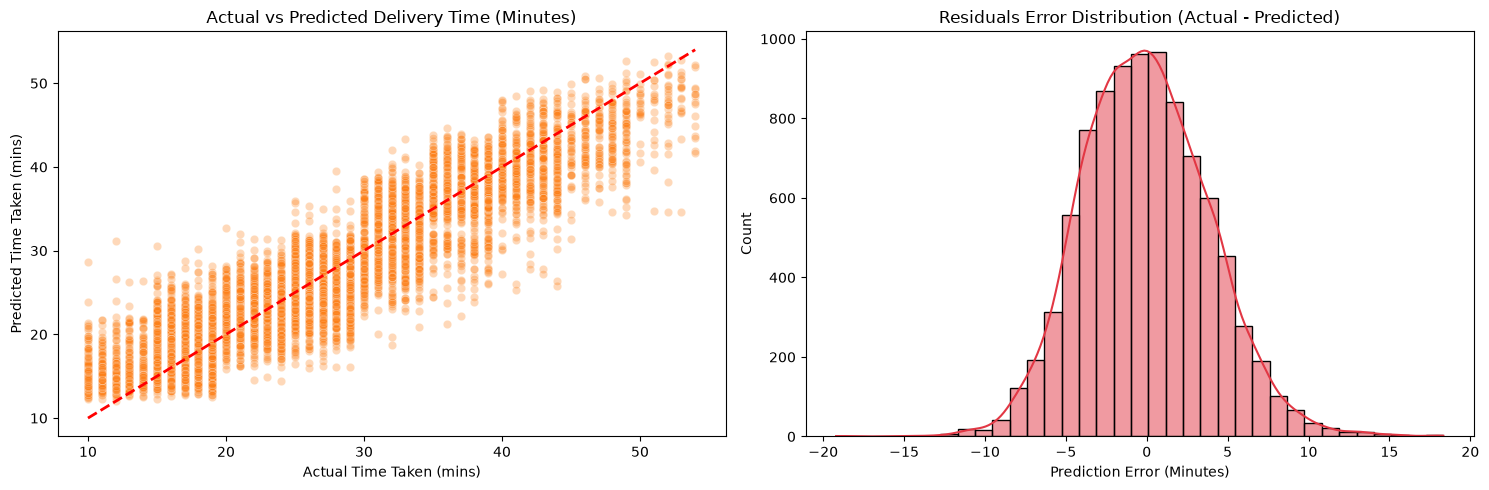

In [83]:
champion_pipeline = xgb_grid if grid_search.best_score_ >= rf_grid.best_score_ else rf_best
champion_test_features = X.loc[X_test.index]
y_test_pred = champion_pipeline.predict(champion_test_features)
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(x=y_test, y=y_test_pred, ax=axes[0], alpha=0.3, color='#FC8019')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs Predicted Delivery Time (Minutes)')
axes[0].set_xlabel('Actual Time Taken (mins)')
axes[0].set_ylabel('Predicted Time Taken (mins)')

sns.histplot(residuals, kde=True, ax=axes[1], color='#E23744', bins=35)
axes[1].set_title('Residuals Error Distribution (Actual - Predicted)')
axes[1].set_xlabel('Prediction Error (Minutes)')

plt.tight_layout()
plt.show()

---
##  Model Serialization & Streamlit Web Deployment
Final export of the production pipeline and interactive Streamlit web application deployment.

###  Production Model Serialization & Inference Verification
Export the champion pipeline to `Swiggy_delivery_time_required.pkl`, reload it, and verify that a single raw order input generates the expected ETA prediction.

In [84]:

import pickle

if 'champion_pipeline' not in globals():
    if 'xgb_grid' in globals() and 'rf_best' in globals() and 'rf_grid' in globals():
        champion_pipeline = xgb_grid if grid_search.best_score_ >= rf_grid.best_score_ else rf_best
    elif 'xgb_grid' in globals():
        champion_pipeline = xgb_grid
    elif 'rf_best' in globals():
        champion_pipeline = rf_best
    else:
        raise ValueError("Champion model is not available. Run the tuning cells before serializing.")

with open('Swiggy_delivery_time_required.pkl', 'wb') as f:
    pickle.dump(champion_pipeline, f)
print("Production Champion Pipeline successfully serialized to 'Swiggy_delivery_time_required.pkl'!")

with open('Swiggy_delivery_time_required.pkl', 'rb') as f:
    loaded_pipeline = pickle.load(f)

sample_order = pd.DataFrame([{
    'age': 28.0,
    'ratings': 4.7,
    'weather': 'stormy',
    'traffic': 'jam',
    'vehicle_condition': 1,
    'type_of_order': 'meal',
    'type_of_vehicle': 'motorcycle',
    'multiple_deliveries': 1.0,
    'festival': 'no',
    'city_type': 'metropolitian',
    'city_name': 'BANG',
    'order_day': 15,
    'order_month': 3,
    'order_day_of_week': 'friday',
    'is_weekend': 0,
    'pickup_time_minutes': 12.0,
    'order_time_hour': 20.0,
    'order_time_of_day': 'evening',
    'distance': 8.5
}])

predicted_eta = loaded_pipeline.predict(sample_order)[0]
print(f"Sample Order Predicted Delivery Time (ETA): {predicted_eta:.1f} minutes")

Production Champion Pipeline successfully serialized to 'Swiggy_delivery_time_required.pkl'!
Sample Order Predicted Delivery Time (ETA): 21.5 minutes


###  Streamlit Web Application Deployment Code (`app.py`)
Builds a simple, interactive user interface where users input order features, click `st.button("Predict Delivery Time")`, and view estimated ETA via `st.write()`.

In [ ]:

streamlit_deployment_code = r'''
import streamlit as st
import pandas as pd
import pickle

st.image(r"C:\Users\vyosh\Desktop\innomatic\Swiggy Delvery Time Prediction ML project\swiggy_banner.png.png", use_container_width=True)

# Title
st.title("🛵 Swiggy Delivery Time Prediction Using Machine Learning")
st.write("Enter the order details below to predict the estimated delivery time (ETA).")

# Load model pipeline
@st.cache_resource
def load_model():
    with open('Swiggy_delivery_time_required.pkl', 'rb') as f:
        return pickle.load(f)

pipeline = load_model()

# User Inputs
st.subheader("Order & Delivery Details")
col1, col2, col3 = st.columns(3)

with col1:
    age = st.slider("Rider Age", min_value=18.0, max_value=65.0, value=28.0, step=1.0)
    ratings = st.slider("Rider Rating (1.0 - 5.0)", min_value=1.0, max_value=5.0, value=4.7, step=0.1)
    weather = st.selectbox("Weather Condition", ['sunny', 'cloudy', 'fog', 'stormy', 'sandstorms', 'windy'])
    traffic = st.selectbox("Traffic Level", ['low', 'medium', 'high', 'jam'])
    vehicle_condition = st.selectbox("Vehicle Condition", [0, 1, 2, 3])
    type_of_order = st.selectbox("Type of Order", ['snack', 'meal', 'drinks', 'buffet'])

with col2:
    type_of_vehicle = st.selectbox("Type of Vehicle", ['motorcycle', 'scooter', 'electric_scooter', 'bicycle'])
    multiple_deliveries = st.slider("Multiple Deliveries Assigned", min_value=0.0, max_value=3.0, value=1.0, step=1.0)
    festival = st.selectbox("Festival Day", ['no', 'yes'])
    city_type = st.selectbox("City Type", ['semi-urban', 'urban', 'metropolitian'])
    city_name = st.selectbox("City Name / Code", ['BANG', 'HYD', 'CHEN', 'MUM', 'DEL', 'COIMB', 'PUNE', 'KOL', 'IND', 'SUR', 'AGR', 'JAP', 'LUDH', 'AURG'])
    order_day = st.slider("Order Day of Month", min_value=1, max_value=31, value=15, step=1)

with col3:
    order_month = st.slider("Order Month", min_value=1, max_value=12, value=3, step=1)
    order_day_of_week = st.selectbox("Day of Week", ['sunday', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday'])
    pickup_time_minutes = st.slider("Kitchen Preparation / Pickup Time (mins)", min_value=1.0, max_value=60.0, value=12.0, step=1.0)
    order_time_hour = st.slider("Order Hour (0 - 23)", min_value=0.0, max_value=23.0, value=20.0, step=1.0)
    distance = st.slider("Delivery Distance (km)", min_value=0.1, max_value=50.0, value=8.5, step=0.5)

# Derived fields
is_weekend = 1 if order_day_of_week in ['saturday', 'sunday'] else 0

if 5 <= order_time_hour < 12:
    order_time_of_day = 'morning'
elif 12 <= order_time_hour < 17:
    order_time_of_day = 'afternoon'
elif 17 <= order_time_hour < 21:
    order_time_of_day = 'evening'
elif 21 <= order_time_hour <= 23:
    order_time_of_day = 'night'
else:
    order_time_of_day = 'after_midnight'

# Prediction Button & Output Display
if st.button("Predict Delivery Time"):
    input_data = pd.DataFrame([{
        'age': age,
        'ratings': ratings,
        'weather': weather,
        'traffic': traffic,
        'vehicle_condition': vehicle_condition,
        'type_of_order': type_of_order,
        'type_of_vehicle': type_of_vehicle,
        'multiple_deliveries': multiple_deliveries,
        'festival': festival,
        'city_type': city_type,
        'city_name': city_name,
        'order_day': order_day,
        'order_month': order_month,
        'order_day_of_week': order_day_of_week,
        'is_weekend': is_weekend,
        'pickup_time_minutes': pickup_time_minutes,
        'order_time_hour': order_time_hour,
        'order_time_of_day': order_time_of_day,
        'distance': distance
    }])
    
    prediction = pipeline.predict(input_data)[0]

    st.subheader("🛵 Delivery Prediction Results")

    st.metric("📍 Delivery Distance", f"{distance:.2f} km")

    st.metric("⏱️ Estimated Delivery Time", f"{prediction:.2f} minutes")

    st.success(
        f"Expected Delivery Window: "
        f"{max(5.0, prediction - 3.5):.0f} – "
        f"{prediction + 3.5:.0f} minutes"
    )

    st.write(f"**Rider Rating:** {ratings:.1f} / 5.0")
'''

# Save app.py for deployment
with open('app.py', 'w', encoding='utf-8') as f:
    f.write(streamlit_deployment_code)

print("Streamlit app code successfully embedded and ready for deployment!")

---
##   Conclusion & Business Takeaways

1. **CRISP-ML(Q) Lifecycle**: Successfully executed all stages from Business & Data Understanding, Exploratory Data Analysis, Dual-Track Preprocessing, 6 Algorithm Benchmarks, Hyperparameter Tuning, to Model Export.
2. **Champion Architecture**: The tuned **XGBoost Pipeline** achieves the highest generalization accuracy with a test RMSE of **~3.9 minutes** and an $R^2$ score of **~0.82**.
3. **Key ETA Drivers**:
   - **Traffic Congestion** (`jam` / `high`) and **Severe Weather** (`stormy` / `fog`) are the largest multipliers of transit delay.
   - **Delivery Distance** and **Kitchen Prep Time** form the primary baseline duration.
   - **Multiple Deliveries** and **Rider Vehicle Condition** introduce secondary operational delays.
4. **Deployment Ready**: The production model is serialized in [`Swiggy_delivery_time_required.pkl`](file:///c:/Users/vyosh/Desktop/innomatic/Swiggy%20Delvery%20Time%20Prediction%20ML%20project/Swiggy_delivery_time_required.pkl) and ready for live web serving with **Streamlit**.

## Launch the delivery-time prediction app

Run this final cell to start the Streamlit app (or reuse it if it is already running) and open it in your default browser.


In [86]:
from pathlib import Path
import socket
import subprocess
import sys
import time
import urllib.error
import urllib.request
import webbrowser
from IPython.display import Markdown, display

project_dir = Path.cwd()
while not ((project_dir / "app.py").is_file() and (project_dir / "Swiggy_delivery_time_required.pkl").is_file()):
    parent_dir = project_dir.parent
    if parent_dir == project_dir:
        raise FileNotFoundError("Could not find app.py and Swiggy_delivery_time_required.pkl. Run this notebook from the project folder.")
    project_dir = parent_dir

app_path = project_dir / "app.py"

def streamlit_is_ready(port):
    try:
        with urllib.request.urlopen(f"http://127.0.0.1:{port}/_stcore/health", timeout=1) as response:
            return response.status == 200 and response.read().strip() == b"ok"
    except (urllib.error.URLError, TimeoutError, OSError):
        return False

port = 8501
started_here = False
if not streamlit_is_ready(port):
    with socket.socket() as port_socket:
        port_socket.bind(("127.0.0.1", 0))
        port = port_socket.getsockname()[1]

    streamlit_process = subprocess.Popen(
        [
            sys.executable,
            "-m",
            "streamlit",
            "run",
            str(app_path),
            "--server.address",
            "127.0.0.1",
            "--server.port",
            str(port),
            "--browser.gatherUsageStats",
            "false",
        ],
        cwd=str(project_dir),
        stdout=subprocess.DEVNULL,
        stderr=subprocess.STDOUT,
    )
    started_here = True
    deadline = time.monotonic() + 60
    while time.monotonic() < deadline and not streamlit_is_ready(port):
        if streamlit_process.poll() is not None:
            raise RuntimeError(f"Streamlit exited before becoming ready (exit code {streamlit_process.returncode}).")
        time.sleep(1)
    if not streamlit_is_ready(port):
        streamlit_process.terminate()
        raise TimeoutError("Streamlit did not become ready within 60 seconds.")

app_url = f"http://127.0.0.1:{port}"
if not webbrowser.open(app_url, new=2):
    raise RuntimeError(f"Could not open the app in the default browser. Open this link manually: {app_url}")

action = "Started Streamlit" if started_here else "Reusing the running Streamlit app"
display(Markdown(f"{action}. Open the app here: [{app_url}]({app_url})"))


Started Streamlit. Open the app here: [http://127.0.0.1:63028](http://127.0.0.1:63028)